# W10_12370245_黃俊翔

繪圖

任意設定一方程式 y = ax + b，[a, b] 初值用個人學號之[ 十位、個位 ] 
如影片迭代每次之運算，逼近 (2,2) (4,4) 點之直線，繪出每次之直線圖形，計算出每次迭代之[a,b] 數值，
迭代至誤差平方總和小於 0.01 止

ps. 梯度下降微分部分請充分看懂

[a, b]=[4, 5]

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([2, 4])
y = np.array([2, 4])
N = len(x)

a = 4.0
b = 5.0
learn_rate = 0.01 

history_a, history_b, history_cost = [], [], []

In [2]:
iteration = 0

while True:
    history_a.append(a)
    history_b.append(b)
    
    y_pred = a * x + b
    error = y_pred - y
    
    cost = np.sum(error ** 2)
    history_cost.append(cost)
    print(f"Iteration {iteration}: a = {a}, b = {b}, SSE = {cost}")
    
    if(cost<0.01):
        break
        
    da = 2 * np.sum(error * x)
    db = 2 * np.sum(error)
    
    a -= learn_rate * da
    b -= learn_rate * db
        
    iteration += 1

Iteration 0: a = 4.0, b = 5.0, SSE = 410.0
Iteration 1: a = 2.2, b = 4.4399999999999995, SSE = 132.1632
Iteration 2: a = 1.1872000000000003, b = 4.118399999999999, SSE = 43.87488768
Iteration 3: a = 0.6181120000000002, b = 3.9311999999999996, SSE = 15.810098503680006
Iteration 4: a = 0.29912320000000014, b = 3.8197785599999996, SSE = 6.879652184339253
Iteration 5: a = 0.12110049280000013, b = 3.7510926335999994, SSE = 4.028677161233341
Iteration 6: a = 0.022529179648000178, b = 3.7065168691199997, SSE = 3.1093736784474557
Iteration 7: a = -0.03126451650559986, b = 3.6755526927974396, SSE = 2.803900407588306
Iteration 8: a = -0.05982503303905269, b = 3.652282327066214, SSE = 2.6935515509142003
Iteration 9: a = -0.0741688990713773, b = 3.633370037948252, SSE = 2.6452950169828324
Iteration 10: a = -0.08050574399661659, b = 3.616935504318887, SSE = 2.616863084016402
Iteration 11: a = -0.08233570691623637, b = 3.601918773425725, SSE = 2.5948257273435997
Iteration 12: a = -0.0816316769608288

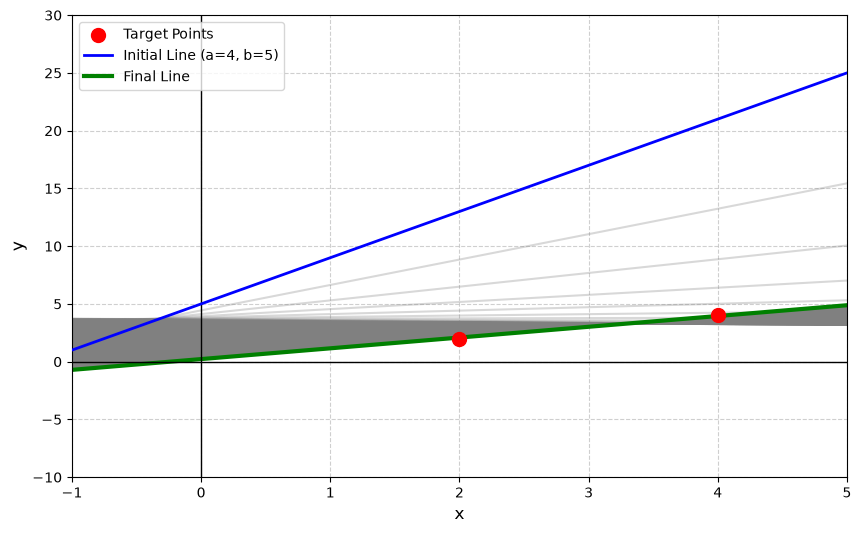

In [3]:
plt.figure(figsize=(10, 6)) 
plt.scatter(x, y, color='red', s=100, zorder=5, label='Target Points')

x_line = np.linspace(-1, 5, 10)

for i in range(len(history_a)):
    if i == 0:
        plt.plot(x_line, history_a[i] * x_line + history_b[i], zorder=4, color='blue', linewidth=2, label='Initial Line (a=4, b=5)')
    elif i == len(history_a) - 1:
        plt.plot(x_line, history_a[i] * x_line + history_b[i], color='green', linewidth=3, label='Final Line')
    else:
        plt.plot(x_line, history_a[i] * x_line + history_b[i], color='gray', alpha=0.3)

plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)

plt.xlim(-1, 5)
plt.ylim(-10, 30) 

plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='black', linewidth=1)

plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()


本次實作成功驗證了梯度下降法，透過每次迭代計算 da 與 
db，最終使誤差平方總和 (SSE) 小於 0.01 達成擬合，觀察發現，
迭代初期的誤差與梯度較大，參數更新步伐劇烈；隨著越來越接近最佳解，
梯度隨之變小，更新步伐逐漸放緩，最終平穩停在誤差最小處

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

x_arr = np.asarray(x)
y_arr = np.asarray(y)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x_arr, y_arr, color='red', s=100, zorder=5, label='Target Points')

x_line = np.linspace(-1, 5, 100)

ax.plot(x_line, history_a[0] * x_line + history_b[0], 
        color='blue', linestyle='--', linewidth=1.5, alpha=0.6, 
        label=f'Initial Line (a={history_a[0]:.1f}, b={history_b[0]:.1f})')

current_line, = ax.plot([], [], color='green', linewidth=3, zorder=4, label='Current Line')
title = ax.set_title('', fontsize=14, fontweight='bold', pad=12)

ax.set_xlim(-1, 5)
ax.set_ylim(-10, 30)
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('y', fontsize=12)
ax.axhline(0, color='black', linewidth=1)
ax.axvline(0, color='black', linewidth=1)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper left')

step = max(1, len(history_a) // 100)
frames_idx = range(0, len(history_a), step)

def update(frame):
    a = history_a[frame]
    b = history_b[frame]
    
    y_line = a * x_line + b
    current_line.set_xdata(x_line)
    current_line.set_ydata(y_line)
    
    ax.plot(x_line, y_line, color='gray', alpha=0.15, linewidth=1, zorder=2)
    
    y_pred = a * x_arr + b
    mse = np.mean((y_arr - y_pred) ** 2)
    
    title.set_text(f'Epoch: {frame} | MSE Loss: {mse:.4f} (a = {a:.3f}, b = {b:.3f})')
    
    return current_line, title

ani = FuncAnimation(fig, update, frames=frames_idx, interval=50, blit=False)

plt.close(fig)
HTML(ani.to_jshtml())

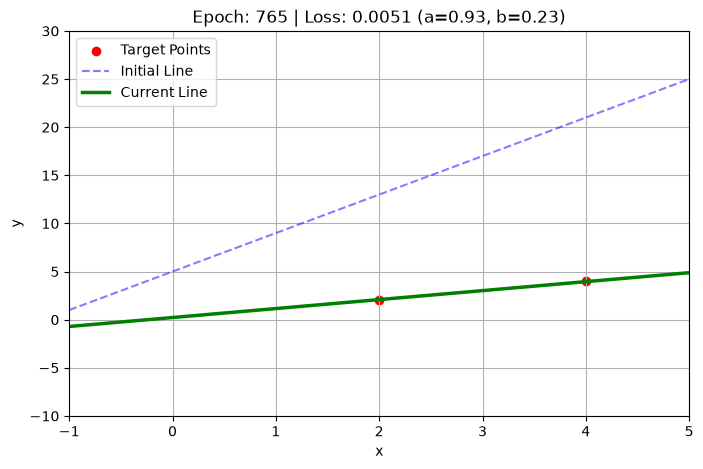

In [7]:
import time
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output

# 1. 準備 X 軸範圍與取樣間隔（最多播 50 幀，避免跑太久）
x_line = np.linspace(-1, 5, 100)
step = max(1, len(history_a) // 50)

# 2. 用簡單 for 迴圈逐幀畫圖
for epoch in range(0, len(history_a), step):
  clear_output(wait=True)  # 清除上一張圖，製造動畫效果

  a = history_a[epoch]
  b = history_b[epoch]
  y_line = a * x_line + b

  # 計算當下的誤差 (MSE)
  mse = np.mean((np.array(y) - (a * np.array(x) + b)) ** 2)

  # 畫出目標點、初始線、目前擬合線
  plt.figure(figsize=(8, 5))
  plt.scatter(x, y, color='red', label='Target Points')
  plt.plot(
      x_line,
      history_a[0] * x_line + history_b[0],
      'b--',
      alpha=0.5,
      label='Initial Line',
  )
  plt.plot(x_line, y_line, 'g-', linewidth=2.5, label='Current Line')

  # 固定座標軸範圍，畫面才不會跳動
  plt.xlim(-1, 5)
  plt.ylim(-10, 30)
  plt.title(f'Epoch: {epoch} | Loss: {mse:.4f} (a={a:.2f}, b={b:.2f})')
  plt.xlabel('x')
  plt.ylabel('y')
  plt.grid(True)
  plt.legend()
  plt.show()

  time.sleep(0.05)  # 控制播放速度

# W10_12370245_黃俊翔
